In [62]:
!pip install -q keras-tuner
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_curve, f1_score

from tensorflow import keras
from tensorflow.keras import layers
import keras_tuner as kt

In [63]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sakhawat18/asteroid-dataset")
df = pd.read_csv(path + "/dataset.csv")
df.head()

Using Colab cache for faster access to the 'asteroid-dataset' dataset.


/tmp/ipykernel_1072/1544841953.py:5: DtypeWarning: Columns (3,4,5) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path + "/dataset.csv")


,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,...,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,...,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,...,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,...,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,...,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,...,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191


For this project, we will only be interested in the numeric features of the dataset to determine whether an asteroid is potentially hazardous.

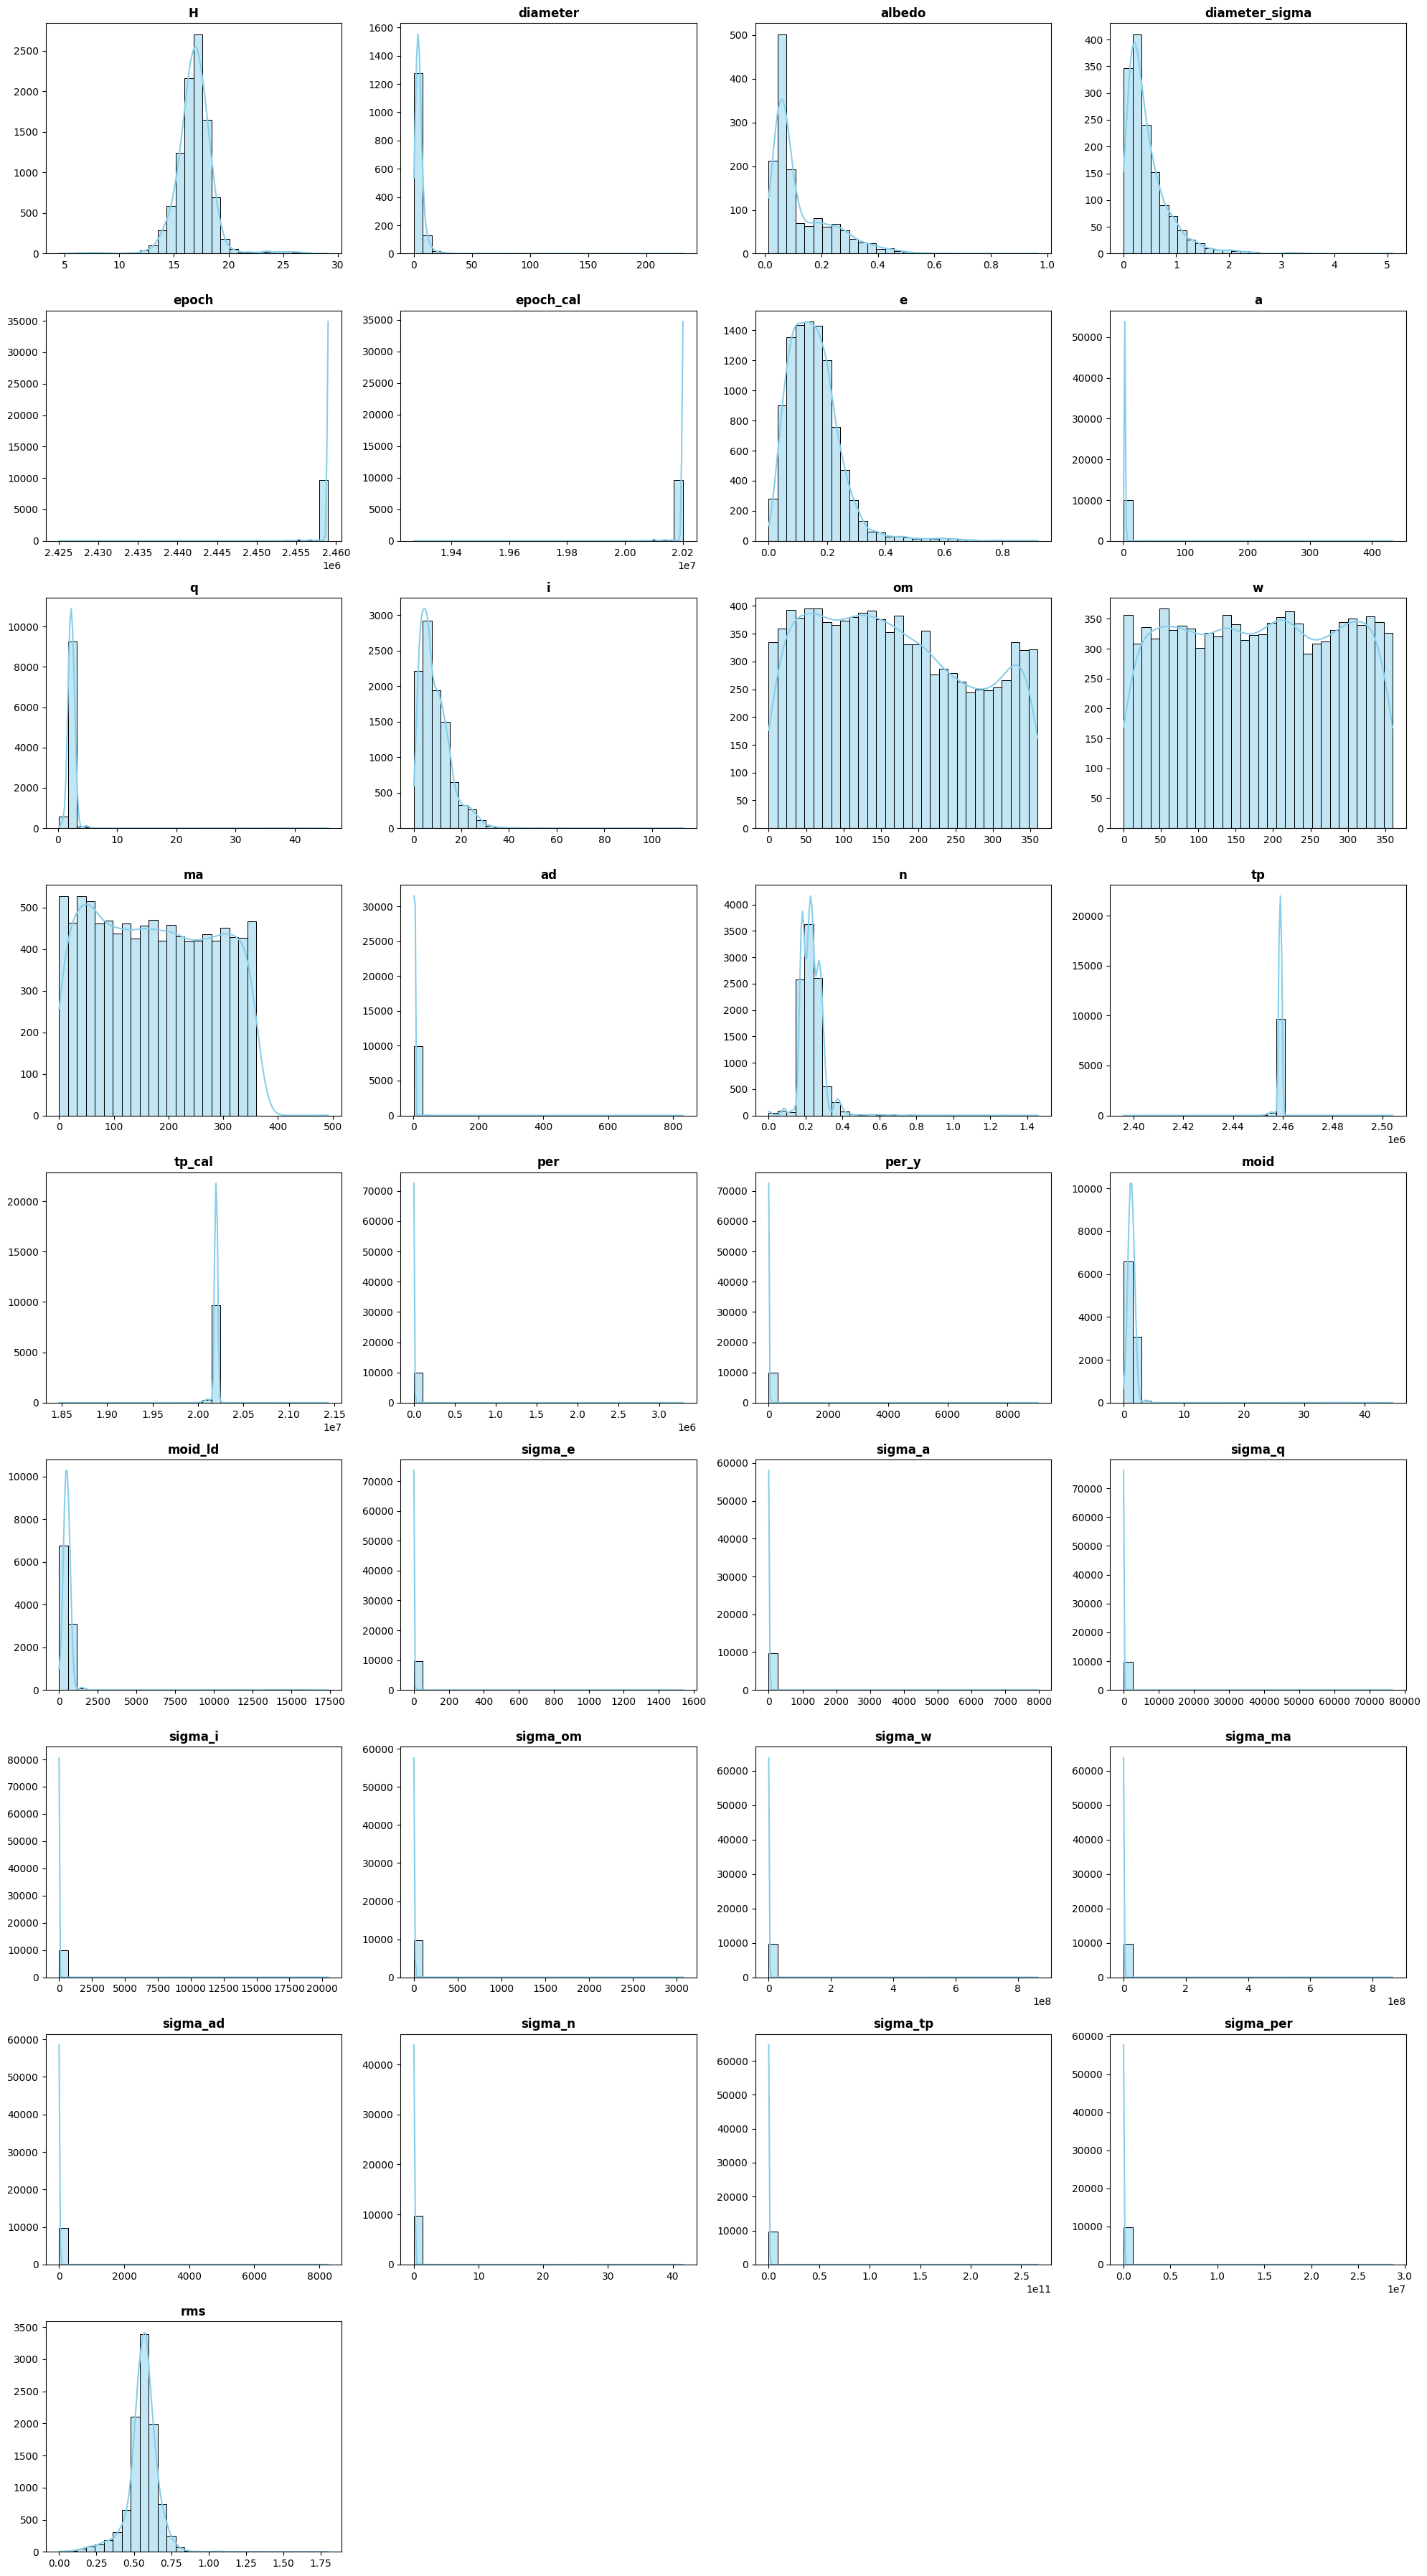

In [64]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

# Filter float64 columns
float_cols = [col for col in df.columns if df[col].dtype == 'float64']

# Sample 10,000 rows for efficient plotting
sample_df = df.sample(n=min(10000, len(df)), random_state=42)

# Set up the plotting grid grid dynamically
n_cols = 4
n_rows = math.ceil(len(float_cols) / n_cols)

fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(20, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(float_cols):
    # Drop NaNs for plotting
    clean_data = sample_df[col].dropna()
    if not clean_data.empty:
        sns.histplot(clean_data, bins=30, ax=axes[i], kde=True, color='skyblue')
    axes[i].set_title(col, fontsize=12, weight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

# Turn off any unused axes
for j in range(len(float_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Many of our features are heavily skewed to the right. Since many of them deal with the dimensions or the makeup of the asteroid, it makes sense since bigger, more massive asteroids are rare, but we would still like to normalize the data for our network. Because `Batchnorm()` cannot fix the scaling on the first layer, we normalize the data with `StandardScaler()` and utilizing `Batchnorm()` in our proceeding hidden layers.

In [65]:
# Drop rows where target variable 'pha' is missing and copy df
clean_df = df.dropna(subset=['pha']).copy()

# Convert categorical target 'Y'/'N' to binary integer 1/0
clean_df['pha'] = clean_df['pha'].map({'Y': 1, 'N': 0})

X = clean_df.copy()
y = X.pop('pha')

transform_num = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler()
)

preprocessor = make_column_transformer(
    (transform_num, float_cols)
)

# Perform a safe 3-way stratified split: 70% train, 15% validation, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(X, y, stratify=y, train_size=0.70, random_state=42)
X_valid, X_test, y_valid, y_test = train_test_split(X_temp, y_temp, stratify=y_temp, train_size=0.50, random_state=42)

# Fit and transform our features
X_train = preprocessor.fit_transform(X_train)
X_valid = preprocessor.transform(X_valid)
X_test = preprocessor.transform(X_test)

input_shape = [X_train.shape[1]]

In [66]:
print("Input shape:", input_shape)

Input shape: [33]


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Final loss: 0.0014385244576260448


<Axes: title={'center': 'Recall'}>

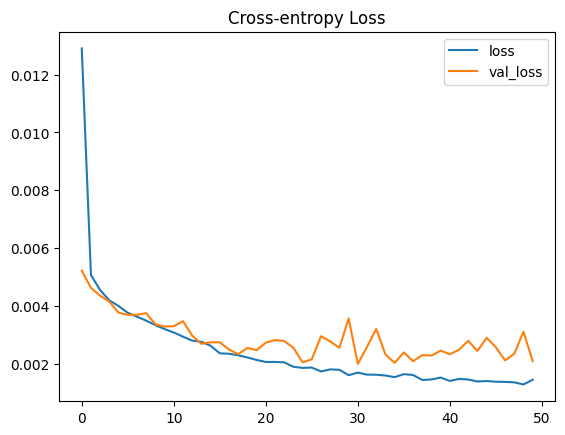

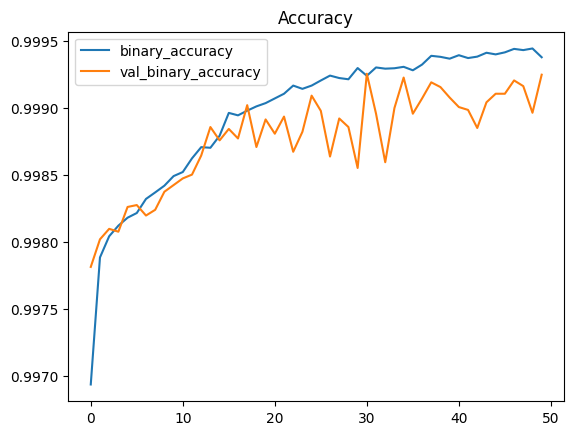

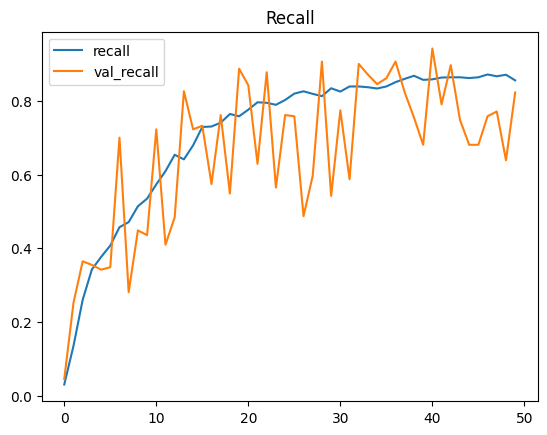

In [67]:
base_model = keras.Sequential([
    layers.Dense(256, activation='relu', input_shape=input_shape),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

base_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        keras.metrics.BinaryAccuracy(name='binary_accuracy'),
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
        keras.metrics.AUC(name='auc')
    ]
)

history = base_model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=512,
    epochs=50,
    verbose=0
)

history_df = pd.DataFrame(history.history)
print("Final loss:", history_df['loss'].iloc[-1])
history_df.loc[:, ['loss', 'val_loss']].plot(title="Cross-entropy Loss")
history_df.loc[:, ['binary_accuracy', 'val_binary_accuracy']].plot(title="Accuracy")
history_df.loc[:, ['recall', 'val_recall']].plot(title="Recall")

In [68]:
print("Final Val loss:", history_df['val_loss'].iloc[-1])
print("Final Val AUCL", history_df['val_auc'].iloc[-1])

Final Val loss: 0.0020848065614700317
Final Val AUCL 0.9868645071983337


Around 15-20 epochs, we see the loss continue to drop smoothly, but validation loss begins to bounce upwards, a textbook sign of overfitting we expected since we didn't add any regularization to the model. We will mitigate this with early stopping and dropout during the hidden layers.

In all our graphs, the validation lines are wildly oscillating, but this because the total percentage of potentially hazardous asteroids is extemely tiny (~0.02%) and even with a 20% validation set, our actual number of positive validation examples is quite small (around 400 total). So when Keras calculates recall, missing or catching a handful of hazardous asteroid creates drastic swings in the recall value from one side to another. This is also why accuracy is not an helpful metric for us as with such a small "positive" sample size, our accuracy will always be incredibly high. Catching potentially hazardous asteroids is a far more important metric both mathematically and interpretation wise.

In [69]:
# implement regularization
early_stopping = keras.callbacks.EarlyStopping(
    patience=10,
    min_delta=0.001,
    restore_best_weights=True
)

# Define a model-building function for Keras Tuner
def build_model(hp):
    model = keras.Sequential([
        layers.Dense(256, activation='relu', input_shape=input_shape),
        layers.Dense(64, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])

    # Use hp.Float to search over the learning rate range
    hp_learning_rate = hp.Float('learning_rate', min_value=1e-4, max_value=1e-2, sampling='log')

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=hp_learning_rate),
        loss='binary_crossentropy',
        metrics=[
            keras.metrics.BinaryAccuracy(name='binary_accuracy'),
            keras.metrics.Precision(name='precision'),
            keras.metrics.Recall(name='recall'),
            keras.metrics.AUC(name='auc')
        ]
    )
    return model

# Instantiate the Hyperband tuner with the model-building function
tuner = kt.RandomSearch(
    build_model,
    objective=kt.Objective("val_auc", direction="max"),
    max_trials=5,
    directory='kt_dir',
    project_name='kt_lr_search'
)

# Search for the best hyperparameters
tuner.search(X_train, y_train, epochs=50, validation_data=(X_valid, y_valid), callbacks=[early_stopping])

best_hps = tuner.get_best_hyperparameters()[0]
print(f"\nBest learning rate: {best_hps.get('learning_rate')}")

Reloading Tuner from kt_dir/kt_lr_search/tuner0.json

Best learning rate: 0.0001752003250330746


In [70]:
best_model = tuner.get_best_models(num_models=1)[0]

val_loss, val_accuracy, val_precision, val_recall, val_auc = best_model.evaluate(X_valid, y_valid)

print(f"Tuned Best Validation AUC: {val_auc}")
print(f"Tuned Best Validation Loss: {val_loss}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


4400/4400 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - auc: 0.9990 - binary_accuracy: 0.9983 - loss: 0.0036 - precision: 0.6445 - recall: 0.5323
Tuned Best Validation AUC: 0.9989974498748779
Tuned Best Validation Loss: 0.003614045912399888


Our validation loss with our tuned learning rate went up, but it gaves us a greater AUC, which like we explained earlier proves far more beneficial to us since AUC measures the area under the ROC curve which has recall on the Y-axis, meaning a greater area correlates to a higher recall rate.

Now we will create two models: one using dropout, and one using BatchNorm so we can study the affect of each of the regularization methods on our models so that when we combine them, we have understanding how each method is affecting our model.

Final loss: 0.004468942992389202


<Axes: title={'center': 'Recall'}>

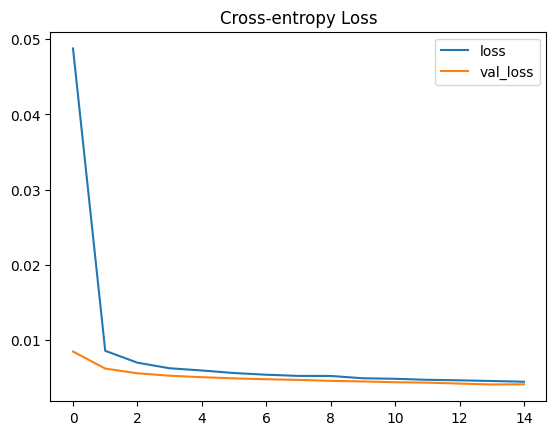

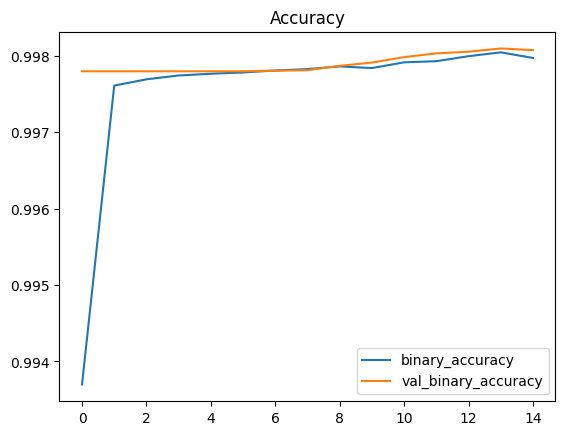

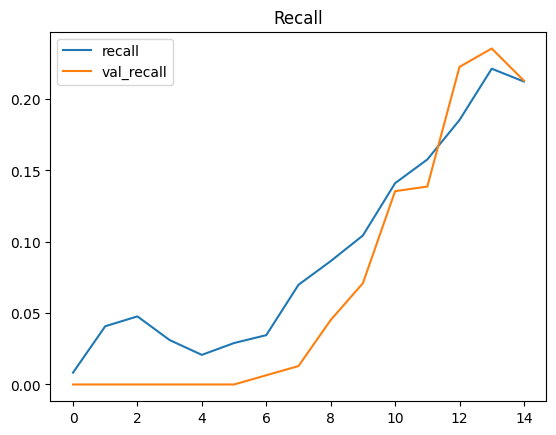

In [71]:
dropout_model = keras.Sequential([
    layers.Dense(256, activation='relu', input_shape=input_shape),
    layers.Dropout(0.5),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

dropout_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=best_hps.get('learning_rate')),
    loss='binary_crossentropy',
    metrics=[
        keras.metrics.BinaryAccuracy(name='binary_accuracy'),
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
        keras.metrics.AUC(name='auc')
    ]
)

history_dropout = dropout_model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=512,
    epochs=50,
    callbacks=[early_stopping],
    verbose=0
)

history_dropout = pd.DataFrame(history_dropout.history)
print("Final loss:", history_dropout['loss'].iloc[-1])
history_dropout.loc[:, ['loss', 'val_loss']].plot(title="Cross-entropy Loss")
history_dropout.loc[:, ['binary_accuracy', 'val_binary_accuracy']].plot(title="Accuracy")
history_dropout.loc[:, ['recall', 'val_recall']].plot(title="Recall")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Final loss: 0.003653026418760419


<Axes: title={'center': 'Recall'}>

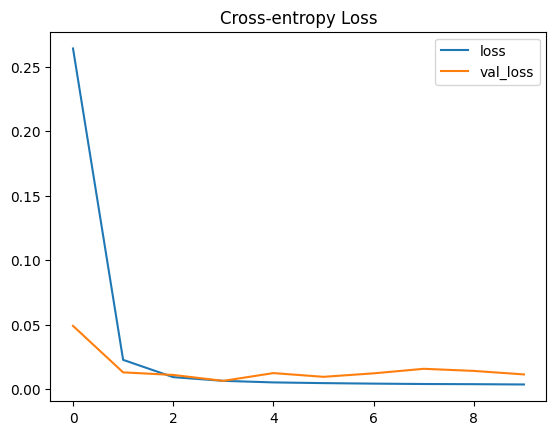

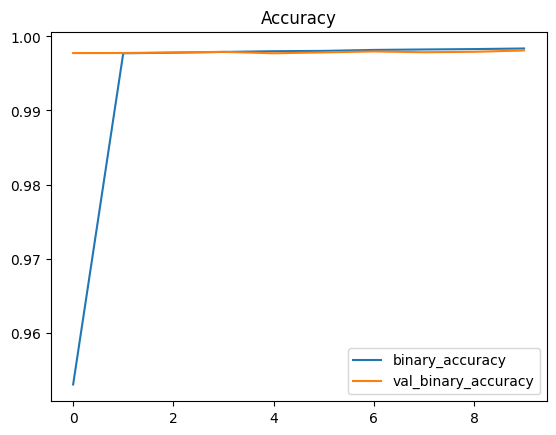

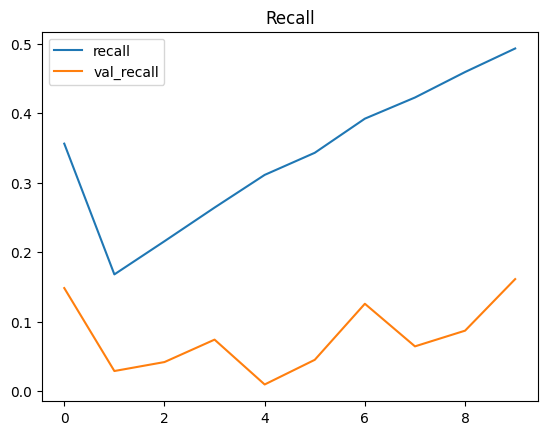

In [72]:
batchnorm_model = keras.Sequential([
    layers.Dense(256, activation='relu', input_shape=input_shape),
    layers.BatchNormalization(),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(1, activation='sigmoid')
])

batchnorm_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=best_hps.get('learning_rate')),
    loss='binary_crossentropy',
    metrics=[
        keras.metrics.BinaryAccuracy(name='binary_accuracy'),
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
        keras.metrics.AUC(name='auc')
    ]
)

history_batchnorm = batchnorm_model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=512,
    epochs=50,
    callbacks=[early_stopping],
    verbose=0
)

history_batchnorm = pd.DataFrame(history_batchnorm.history)
print("Final loss:", history_batchnorm['loss'].iloc[-1])
history_batchnorm.loc[:, ['loss', 'val_loss']].plot(title="Cross-entropy Loss")
history_batchnorm.loc[:, ['binary_accuracy', 'val_binary_accuracy']].plot(title="Accuracy")
history_batchnorm.loc[:, ['recall', 'val_recall']].plot(title="Recall")

In [73]:
# Base Model vs Dropout vs BatchNorm
print("Base Model vs Dropout vs BatchNorm")
print("Validation Loss:", history_df['val_loss'].iloc[-1], "vs", history_dropout['val_loss'].iloc[-1], "vs", history_batchnorm['val_loss'].iloc[-1])
print("Validation AUC:", history_df['val_auc'].iloc[-1], "vs", history_dropout['val_auc'].iloc[-1], "vs", history_batchnorm['val_auc'].iloc[-1])
print("Validation Recall:", history_df['val_recall'].iloc[-1], "vs", history_dropout['val_recall'].iloc[-1], "vs", history_batchnorm['val_recall'].iloc[-1])

Base Model vs Dropout vs BatchNorm
Validation Loss: 0.0020848065614700317 vs 0.00412908336147666 vs 0.011452486738562584
Validation AUC: 0.9868645071983337 vs 0.996938169002533 vs 0.9974705576896667
Validation Recall: 0.8225806355476379 vs 0.21290323138237 vs 0.16129031777381897


we see dropout help cut the gap between training and validation loss, and Batchnorm helped reduced the wild oscillation we were seeing. We see that recall is reduced in both models, and this is once again because of the class imbalance. We will try and fix this with lowering dropout amount and introducing class_weight.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Final loss: 0.037756603211164474


<Axes: title={'center': 'Recall'}>

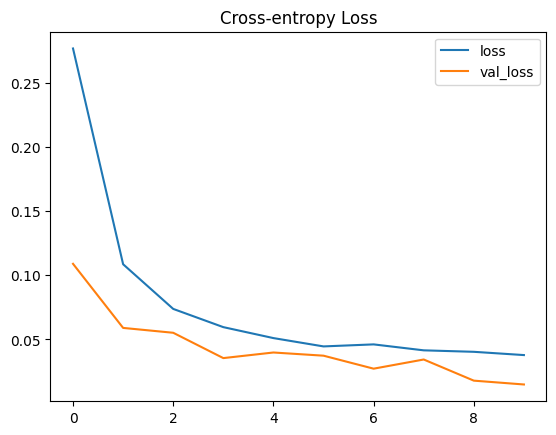

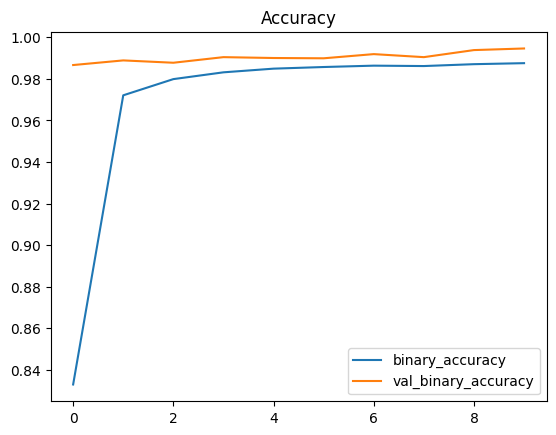

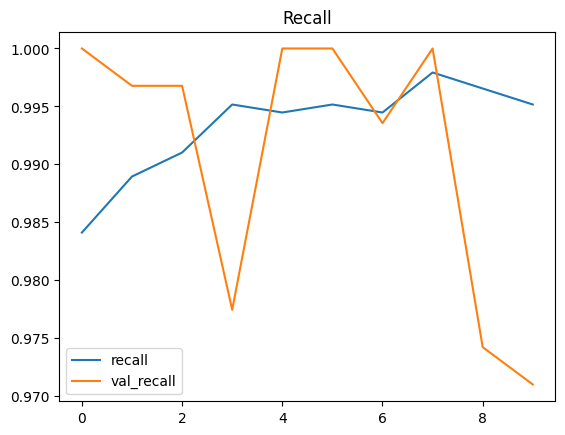

In [74]:
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = dict(enumerate(class_weights))

final_model = keras.Sequential([
    layers.Dense(256, activation='relu', input_shape=input_shape),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid')
])

final_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=best_hps.get('learning_rate')),
    loss='binary_crossentropy',
    metrics=[
        keras.metrics.BinaryAccuracy(name='binary_accuracy'),
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
        keras.metrics.AUC(name='auc')
    ]
)

history_final_model = final_model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=512,
    epochs=50,
    callbacks=[early_stopping],
    class_weight=class_weight_dict,
    verbose=0
)

history_final_model = pd.DataFrame(history_final_model.history)
print("Final loss:", history_final_model['loss'].iloc[-1])
history_final_model.loc[:, ['loss', 'val_loss']].plot(title="Cross-entropy Loss")
history_final_model.loc[:, ['binary_accuracy', 'val_binary_accuracy']].plot(title="Accuracy")
history_final_model.loc[:, ['recall', 'val_recall']].plot(title="Recall")

In [75]:
# Base Model vs Dropout vs BatchNorm
print("Base Model vs Final Model")
print("Validation Loss:", history_df['val_loss'].iloc[-1], "vs", history_final_model['val_loss'].iloc[-1])
print("Validation AUC:", history_df['val_auc'].iloc[-1], "vs", history_final_model['val_auc'].iloc[-1])
print("Validation Recall:", history_df['val_recall'].iloc[-1], "vs", history_final_model['val_recall'].iloc[-1])
print("Validation Precision:", history_df['val_precision'].iloc[-1], "vs", history_final_model['val_precision'].iloc[-1])

Base Model vs Final Model
Validation Loss: 0.0020848065614700317 vs 0.01485801488161087
Validation AUC: 0.9868645071983337 vs 0.9977803826332092
Validation Recall: 0.8225806355476379 vs 0.9709677696228027
Validation Precision: 0.8333333134651184 vs 0.2866666615009308


In [76]:
y_pred_probs = final_model.predict(X_valid)
y_pred = (y_pred_probs >= 0.5).astype(int)

# Print confusion matrix and full report
print(confusion_matrix(y_valid, y_pred))
print(classification_report(y_valid, y_pred))

4400/4400 ━━━━━━━━━━━━━━━━━━━━ 5s 1ms/step
[[138600   1880]
 [     0    310]]
              precision    recall  f1-score   support

           0       1.00      0.99      0.99    140480
           1       0.14      1.00      0.25       310

    accuracy                           0.99    140790
   macro avg       0.57      0.99      0.62    140790
weighted avg       1.00      0.99      0.99    140790



While we raised the validation AUC and got the recall value to 1 (which is to be expected as we'll explain at the end), we got way too low of a precision, which means our model has too low of a threshold and is playing it safe. Let's plot a PR curve to find a better threshold.

4400/4400 ━━━━━━━━━━━━━━━━━━━━ 5s 1ms/step
Optimal Threshold (maximizing F1): 0.8044
Corresponding Precision: 0.2331
Corresponding Recall: 0.8323


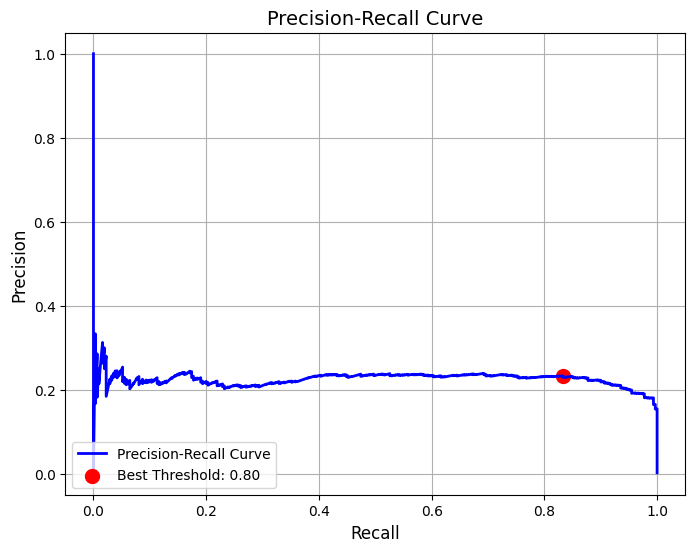


Confusion Matrix with Optimal Threshold:
[[139631    849]
 [    52    258]]

Classification Report with Optimal Threshold:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00    140480
           1       0.23      0.83      0.36       310

    accuracy                           0.99    140790
   macro avg       0.62      0.91      0.68    140790
weighted avg       1.00      0.99      1.00    140790



In [77]:
# 1. Get raw prediction probabilities for the validation set
y_pred_probs = final_model.predict(X_valid).ravel()

# 2. Compute precision, recall, and thresholds
precisions, recalls, thresholds = precision_recall_curve(y_valid, y_pred_probs)

# 3. Find the optimal threshold (e.g., maximizing the F1-score)
# Note: thresholds has one less element than precisions/recalls
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print(f"Optimal Threshold (maximizing F1): {best_threshold:.4f}")
print(f"Corresponding Precision: {precisions[best_index]:.4f}")
print(f"Corresponding Recall: {recalls[best_index]:.4f}")

# 4. Plot the Precision-Recall curve
plt.figure(figsize=(8, 6))
plt.plot(recalls, precisions, label='Precision-Recall Curve', color='b', linewidth=2)
plt.scatter(recalls[best_index], precisions[best_index], color='red', s=100, label=f'Best Threshold: {best_threshold:.2f}')
plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Precision-Recall Curve', fontsize=14)
plt.legend(loc='lower left')
plt.grid(True)
plt.show()

# 5. Evaluate performance using this new threshold
y_pred_optimal = (y_pred_probs >= best_threshold).astype(int)

from sklearn.metrics import confusion_matrix, classification_report
print("\nConfusion Matrix with Optimal Threshold:")
print(confusion_matrix(y_valid, y_pred_optimal))
print("\nClassification Report with Optimal Threshold:")
print(classification_report(y_valid, y_pred_optimal))

Here now we sacrificed some of the recall value to increase precision. Now that we have our optimized threshold, we can finally run our model on the test set. We caught 78% of all potentially hazardous asteroids whil keeping false positives down (978), and because these metrics match closely with the validation (~23% precision, ~83% recall) it means our model did not overfit like we regularized it for.

This dataset took data from NASA, and the organization actually has a definition for classifying Potentially Hazardous Asteroids (PHAs), primarily using **Absolute Magnitude** (H $\le$ 22) and **Minimum Orbit Intersection Distance** (MOID $\le$ 0.05). 98.12% of our flagged asteroids met this criteria, meaning we did a good job reaching a similar conclusion to NASA.

In [78]:
y_test_prob = final_model.predict(X_test).ravel()
y_test_pred = (y_test_prob >= best_threshold).astype(int)

print("=== Final Test Set Evaluation ===")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

4400/4400 ━━━━━━━━━━━━━━━━━━━━ 5s 1ms/step
=== Final Test Set Evaluation ===

Confusion Matrix:
[[139554    927]
 [    68    242]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00    140481
           1       0.21      0.78      0.33       310

    accuracy                           0.99    140791
   macro avg       0.60      0.89      0.66    140791
weighted avg       1.00      0.99      0.99    140791



In [79]:
y_test_arr = np.array(y_test)

np.random.seed(42)
random_indices = np.random.choice(len(X_test), size=25, replace=False)

sample_X = X_test.iloc[random_indices] if isinstance(X_test, pd.DataFrame) else X_test[random_indices]
sample_y_true = y_test_arr[random_indices]
sample_probs = y_test_prob[random_indices]
sample_preds = (sample_probs >= 0.8627).astype(int)

sample_results = pd.DataFrame({
    'True Label (0=Safe, 1=Hazardous)': sample_y_true,
    'Model Prediction': sample_preds,
    'Confidence Score': sample_probs
})

print("=== Random 25 Test Predictions ===")
display(sample_results)

=== Random 25 Test Predictions ===


,"True Label (0=Safe, 1=Hazardous)",Model Prediction,Confidence Score
0,0,0,0.077495
1,0,0,0.073435
2,0,0,0.202507
3,0,0,0.057282
4,0,0,0.056508
5,0,0,0.063024
6,0,0,0.052954
7,0,0,0.064554
8,0,0,0.059117
9,0,0,0.059120


In [80]:
predicted_hazardous_mask = (y_test_prob >= best_threshold)
flagged_asteroids = X_test.loc[predicted_hazardous_mask]

nasa_hazardous_mask = (flagged_asteroids['H'] <= 22) & (flagged_asteroids['moid'] <= 0.05)

total_flagged = len(flagged_asteroids)
matching_nasa = nasa_hazardous_mask.sum()
percentage_matching = (matching_nasa / total_flagged) * 100 if total_flagged > 0 else 0

print("=== NASA Definition Alignment Check ===")
print(f"Total asteroids flagged as hazardous by our model: {total_flagged}")
print(f"Asteroids among those matching NASA's definition (H <= 22 & MOID <= 0.05): {matching_nasa}")
print(f"Alignment Percentage: {percentage_matching:.2f}%")

=== NASA Definition Alignment Check ===
Total asteroids flagged as hazardous by our model: 1169
Asteroids among those matching NASA's definition (H <= 22 & MOID <= 0.05): 1147
Alignment Percentage: 98.12%


## FINAL NOTE

While we were able to get good values for precision, recall, and matching NASA's definition for potentially hazardous asteroids closely, it is important to note that this project was a great deep dive into Neural Networks, but NN is not an optimal model for this dataset. Because NASA's definition follows logical, boolean splits, a very simple Decision Tree would have easily found those metrics and kept the precision and recall perfect 1.0.